In [2]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 3.5.5


In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("SpotifyPreprocessing")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.5


In [21]:
import requests

url = "http://localhost:9871/webhdfs/v1/?op=LISTSTATUS"

response = requests.get(url)

print("Status:", response.status_code)
print(response.text)

Status: 200
{"FileStatuses":{"FileStatus":[
{"accessTime":0,"blockSize":0,"childrenNum":1,"fileId":16386,"group":"supergroup","length":0,"modificationTime":1790522581113,"owner":"root","pathSuffix":"rmstate","permission":"755","replication":0,"storagePolicy":0,"type":"DIRECTORY"},
{"accessTime":0,"blockSize":0,"childrenNum":1,"fileId":16397,"group":"supergroup","length":0,"modificationTime":1790526538648,"owner":"Joy","pathSuffix":"test_spotify","permission":"755","replication":0,"storagePolicy":0,"type":"DIRECTORY"}
]}}



In [23]:
import requests

url = (
    "http://localhost:9871/webhdfs/v1/"
    "test_spotify/webhdfs_test.txt"
    "?op=CREATE&overwrite=true"
)

response = requests.put(url, allow_redirects=False)

print("Status:", response.status_code)
print("Location:", response.headers.get("Location"))

Status: 307
Location: http://9cbd9f2a4b50:9864/webhdfs/v1/test_spotify/webhdfs_test.txt?op=CREATE&namenoderpcaddress=namenode:9000&createflag=&createparent=true&overwrite=true


In [24]:
import requests

url = (
    "http://localhost:9871/webhdfs/v1/"
    "test_spotify/webhdfs_test.txt"
    "?op=CREATE&overwrite=true"
)

response = requests.put(url, allow_redirects=False)

redirect_url = response.headers["Location"]

redirect_url = redirect_url.replace(
    "9cbd9f2a4b50:9864",
    "localhost:9864"
)

print("Original:", response.headers["Location"])
print("Modified:", redirect_url)

Original: http://9cbd9f2a4b50:9864/webhdfs/v1/test_spotify/webhdfs_test.txt?op=CREATE&namenoderpcaddress=namenode:9000&createflag=&createparent=true&overwrite=true
Modified: http://localhost:9864/webhdfs/v1/test_spotify/webhdfs_test.txt?op=CREATE&namenoderpcaddress=namenode:9000&createflag=&createparent=true&overwrite=true


In [25]:
import requests

# Step 1: Ask NameNode where to create the file
create_url = (
    "http://localhost:9871/webhdfs/v1/"
    "test_spotify/webhdfs_test.txt"
    "?op=CREATE&overwrite=true"
)

response = requests.put(create_url, allow_redirects=False)

# Step 2: Replace Docker's internal DataNode address
upload_url = response.headers["Location"].replace(
    response.headers["Location"].split("/")[2],
    "localhost:9864"
)

# Step 3: Send the actual file contents to DataNode
upload_response = requests.put(
    upload_url,
    data=b"Hello from Jupyter + WebHDFS!"
)

print("Create response:", response.status_code)
print("Upload response:", upload_response.status_code)
print(upload_response.text)

Create response: 307
Upload response: 201



In [26]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Joy\docker-hadoop-2\notebooks
['spotify_preprocessing.ipynb']


In [28]:
import os

csv_path = r"C:\Users\Joy\Desktop\spotify-tracks-dataset-detailed.csv"

print("Path:", csv_path)
print("Exists:", os.path.exists(csv_path))
print("Is file:", os.path.isfile(csv_path))

Path: C:\Users\Joy\Desktop\spotify-tracks-dataset-detailed.csv
Exists: True
Is file: True


In [21]:
csv_path = "file:///C:/Users/Joy/Desktop/spotify-tracks-dataset-detailed.csv"

df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("quote", '"')
    .option("escape", '"')
    .csv(csv_path)
)

print("Rows:", df.count())
print("Columns:", len(df.columns))

df.printSchema()

Rows: 21639
Columns: 20
root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: integer (nullable = true)
 |-- track_genre: string (nullable = true)



In [22]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo",
    "speechiness",
    "instrumentalness",
    "liveness"
]

print("Audio features:", audio_features)

Audio features: ['danceability', 'energy', 'loudness', 'acousticness', 'valence', 'tempo', 'speechiness', 'instrumentalness', 'liveness']


In [30]:
# Display the data types of all columns
df.printSchema()

# Count missing values in each column
from pyspark.sql.functions import col, sum

missing = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

missing.show()

root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: string (nullable = true)
 |-- duration_ms: string (nullable = true)
 |-- explicit: string (nullable = true)
 |-- danceability: string (nullable = true)
 |-- energy: string (nullable = true)
 |-- key: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: string (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: double (nullable = true)
 |-- track_genre: string (nullable = true)

+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+----

In [31]:
from pyspark.sql.functions import col

df = (
    df
    .withColumn("popularity", col("popularity").cast("double"))
    .withColumn("duration_ms", col("duration_ms").cast("double"))
    .withColumn("danceability", col("danceability").cast("double"))
    .withColumn("energy", col("energy").cast("double"))
    .withColumn("mode", col("mode").cast("double"))
    .withColumn("explicit", col("explicit").cast("boolean"))
)

df.printSchema()

root
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: double (nullable = true)
 |-- duration_ms: double (nullable = true)
 |-- explicit: boolean (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: double (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: double (nullable = true)
 |-- track_genre: string (nullable = true)



In [32]:
from pyspark.sql.functions import count

total_rows = df.count()
unique_tracks = df.select("track_id").distinct().count()

print("Total rows:", total_rows)
print("Unique track IDs:", unique_tracks)
print("Duplicate rows based on track_id:", total_rows - unique_tracks)

Total rows: 21639
Unique track IDs: 20432
Duplicate rows based on track_id: 1207


In [33]:
from pyspark.sql.functions import col, count

duplicate_ids = (
    df.groupBy("track_id")
      .count()
      .filter(col("count") > 1)
)

duplicate_ids.orderBy(col("count").desc()).show(10)

+--------------------+-----+
|            track_id|count|
+--------------------+-----+
|41cDKFuTigPfBWyLY...|    3|
|3dPQuX8Gs42Y7b454...|    3|
|5ftfVzSLIi5ZxYdNb...|    3|
|6MCy7TQ6qOvEdayIk...|    3|
|5BI1XqMJK91dsEq0B...|    3|
|2aibwv5hGXSgw7Yru...|    3|
|4JuKzBOcFT6ZDX1bI...|    3|
|23PvWFdi76vER4p1e...|    3|
|27sytaeEm6TDVMpdE...|    3|
|7BDQlgM0pemXy3b4A...|    3|
+--------------------+-----+
only showing top 10 rows



In [34]:
sample_duplicate_id = (
    duplicate_ids
    .orderBy(col("count").desc())
    .first()["track_id"]
)

print("Track ID:", sample_duplicate_id)

df.filter(col("track_id") == sample_duplicate_id) \
  .select(
      "track_id",
      "track_name",
      "artists",
      "album_name",
      "track_genre",
      "popularity",
      "danceability",
      "energy",
      "tempo"
  ) \
  .show(truncate=False)

Track ID: 4JuKzBOcFT6ZDX1bINNI1C
+----------------------+-----------+-----------+-----------+-----------+----------+------------+------+-------+
|track_id              |track_name |artists    |album_name |track_genre|popularity|danceability|energy|tempo  |
+----------------------+-----------+-----------+-----------+-----------+----------+------------+------+-------+
|4JuKzBOcFT6ZDX1bINNI1C|Honeybrains|Royal Blood|Hot Mix Pop|alt-rock   |1.0       |0.523       |0.8   |125.886|
|4JuKzBOcFT6ZDX1bINNI1C|Honeybrains|Royal Blood|Hot Mix Pop|alternative|1.0       |0.523       |0.8   |125.886|
|4JuKzBOcFT6ZDX1bINNI1C|Honeybrains|Royal Blood|Hot Mix Pop|blues      |1.0       |0.523       |0.8   |125.886|
+----------------------+-----------+-----------+-----------+-----------+----------+------------+------+-------+



In [39]:
from pyspark.sql.functions import min, max

audio_features = [
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo",
    "speechiness",
    "instrumentalness",
    "liveness"
]

df.select([
    min(col(c)).alias(f"{c}_min") for c in audio_features
] + [
    max(col(c)).alias(f"{c}_max") for c in audio_features
]).show(truncate=False)

+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+
|danceability_min|energy_min|loudness_min|acousticness_min|valence_min|tempo_min|speechiness_min|instrumentalness_min|liveness_min|danceability_max|energy_max|loudness_max|acousticness_max|valence_max|tempo_max|speechiness_max|instrumentalness_max|liveness_max|
+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+
|0.0             |7.56E-4   |-41.808     |0.0             |0.0        |0.0      |0.0            |0.0                 |0.0116      |0.981           |1.0       |4.532       |0.996           |0.995      |243.372  |0.9

In [40]:
df.filter(
    col("loudness") > 0
).select(
    "track_id",
    "track_name",
    "artists",
    "loudness"
).show(20, truncate=False)

+----------------------+------------------------------+--------------------------------+--------+
|track_id              |track_name                    |artists                         |loudness|
+----------------------+------------------------------+--------------------------------+--------+
|4KQTgmkSEBzsGS3qL1aX7G|それは小さな光のような        |Sayuri                          |0.698   |
|7FOeR1X65DEG4KjpVhNC4Z|それは小さな光のような        |Sayuri                          |0.698   |
|2aRWAz05qiQ9j5HgX7xNHC|Stigma - Burr Oak Remix       |Noisia;Burr Oak                 |0.025   |
|3yqoJ4rc45ep4M0iLa32rC|Ganja - Deekline & Kleu Remix |Dub Pistols;Deekline;Kleu       |0.082   |
|5TTJq1w8bLnUHweg924HfI|STARS                         |DJ Fixx                         |0.202   |
|3InXaDH9pCnoGG8dkwtXUT|Get Lucky - Nick The Lot Remix|Deekline;Specimen A;Nick The Lot|0.194   |
|0HfHtjS9S9q4DGVC3uIIRB|Fate Dance                    |Five Star Hotel                 |4.532   |
|4LM77KZM8EgPn9nKk7TdT5|Eternity or Someth

In [23]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

assembler = VectorAssembler(
    inputCols=audio_features,
    outputCol="features"
)

df_features = assembler.transform(df)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(df_features)

df_scaled = scaler_model.transform(df_features)

print("Feature vector + standardization completed.")
print("Rows:", df_scaled.count())

Feature vector + standardization completed.
Rows: 21639


In [24]:
from pyspark.ml.clustering import KMeans

k6_kmeans = KMeans(
    k=6,
    seed=42,
    featuresCol="scaled_features",
    predictionCol="cluster"
)

k6_model = k6_kmeans.fit(df_scaled)

k6_predictions = k6_model.transform(df_scaled)

print("K-Means completed.")
print("Rows:", k6_predictions.count())

K-Means completed.
Rows: 21639


In [25]:
final_df = k6_predictions.select(
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre",
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo",
    "speechiness",
    "instrumentalness",
    "liveness",
    "cluster"
)

print("final_df created")
print("Rows:", final_df.count())
print("Columns:", len(final_df.columns))

final_df.printSchema()

final_df created
Rows: 21639
Columns: 16
root
 |-- track_id: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_genre: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- cluster: integer (nullable = false)



In [41]:
from pyspark.sql.functions import col, sum

df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|track_id|artists|album_name|track_name|popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|tempo|time_signature|track_genre|
+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|       0|      0|         0|         0|         0|          0|       0|           0|     0|  0|       0|   0|          0|           0|               0|       0|      0|    0|             0|          0|
+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+-------------

In [42]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

audio_features = [
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo",
    "speechiness",
    "instrumentalness",
    "liveness"
]

assembler = VectorAssembler(
    inputCols=audio_features,
    outputCol="features"
)

df_features = assembler.transform(df)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(df_features)

df_scaled = scaler_model.transform(df_features)

df_scaled.select(
    "track_id",
    "track_name",
    "features",
    "scaled_features"
).show(5, truncate=False)

+----------------------+--------------------------+--------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|track_id              |track_name                |features                                                      |scaled_features                                                                                                                                                                       |
+----------------------+--------------------------+--------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|5SuOikwiRyPMVoIQDJUgSV|Comedy                    |[0.676,0.461,-6.746,0.0322,0.715,87.917,0.143,1.01E-6,0

In [28]:
from pyspark.sql.functions import col, min, max

df.select(
    *[
        min(col(c)).alias(f"{c}_min")
        for c in audio_features
    ],
    *[
        max(col(c)).alias(f"{c}_max")
        for c in audio_features
    ]
).show(truncate=False)

+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+
|danceability_min|energy_min|loudness_min|acousticness_min|valence_min|tempo_min|speechiness_min|instrumentalness_min|liveness_min|danceability_max|energy_max|loudness_max|acousticness_max|valence_max|tempo_max|speechiness_max|instrumentalness_max|liveness_max|
+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+----------------+----------+------------+----------------+-----------+---------+---------------+--------------------+------------+
|0.0             |7.56E-4   |-41.808     |0.0             |0.0        |0.0      |0.0            |0.0                 |0.0116      |0.981           |1.0       |4.532       |0.996           |0.995      |243.372  |0.9

In [29]:
from pyspark.sql.functions import col, sum as spark_sum

null_counts = df.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in audio_features
])

null_counts.show()

+------------+------+--------+------------+-------+-----+-----------+----------------+--------+
|danceability|energy|loudness|acousticness|valence|tempo|speechiness|instrumentalness|liveness|
+------------+------+--------+------------+-------+-----+-----------+----------------+--------+
|           0|     0|       0|           0|      0|    0|          0|               0|       0|
+------------+------+--------+------------+-------+-----+-----------+----------------+--------+



In [44]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

kmeans = KMeans(
    k=2,
    seed=42,
    featuresCol="scaled_features",
    predictionCol="cluster"
)

model = kmeans.fit(df_scaled)

predictions = model.transform(df_scaled)

predictions.select("cluster").groupBy("cluster").count().show()

evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

score = evaluator.evaluate(predictions)

print("Silhouette Score:", score)

+-------+-----+
|cluster|count|
+-------+-----+
|      1|15726|
|      0| 5913|
+-------+-----+

Silhouette Score: 0.42330066740536476


In [46]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        k=k,
        seed=42,
        featuresCol="scaled_features",
        predictionCol="cluster"
    )

    model = kmeans.fit(df_scaled)
    predictions = model.transform(df_scaled)

    score = evaluator.evaluate(predictions)
    silhouette_scores.append((k, score))

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4233
K = 3, Silhouette Score = 0.2563
K = 4, Silhouette Score = 0.3222
K = 5, Silhouette Score = 0.3193
K = 6, Silhouette Score = 0.3526
K = 7, Silhouette Score = 0.3140
K = 8, Silhouette Score = 0.3279
K = 9, Silhouette Score = 0.3139
K = 10, Silhouette Score = 0.3015


In [49]:
from pyspark.ml.clustering import KMeans

final_kmeans = KMeans(
    k=2,
    seed=42,
    featuresCol="scaled_features",
    predictionCol="cluster"
)

final_model = final_kmeans.fit(df_scaled)

final_predictions = final_model.transform(df_scaled)

final_predictions.groupBy("cluster").count().orderBy("cluster").show()

+-------+-----+
|cluster|count|
+-------+-----+
|      0| 5913|
|      1|15726|
+-------+-----+



In [50]:
from pyspark.sql.functions import avg, col

cluster_summary = (
    final_predictions
    .groupBy("cluster")
    .agg(
        *[
            avg(col(feature)).alias(feature)
            for feature in audio_features
        ]
    )
    .orderBy("cluster")
)

cluster_summary.show(truncate=False)

+-------+-------------------+-------------------+------------------+-------------------+------------------+------------------+-------------------+-------------------+-------------------+
|cluster|danceability       |energy             |loudness          |acousticness       |valence           |tempo             |speechiness        |instrumentalness   |liveness           |
+-------+-------------------+-------------------+------------------+-------------------+------------------+------------------+-------------------+-------------------+-------------------+
|0      |0.47017114831726614|0.28046510502283156|-15.31329206832411|0.788770026027398  |0.3074497378657207|110.34281210891245|0.10658530356840841|0.3448997611246411 |0.20167508878741688|
|1      |0.6054838992750868 |0.7189083047182993 |-6.824827038026143|0.20698266178367158|0.5405027025308391|123.87888286913444|0.10327251685107468|0.14114062315274065|0.21552211624061893|
+-------+-------------------+-------------------+----------------

In [51]:
from pyspark.ml.clustering import KMeans

k6_kmeans = KMeans(
    k=6,
    seed=42,
    featuresCol="scaled_features",
    predictionCol="cluster"
)

k6_model = k6_kmeans.fit(df_scaled)

k6_predictions = k6_model.transform(df_scaled)

k6_predictions.groupBy("cluster").count().orderBy("cluster").show()

+-------+-----+
|cluster|count|
+-------+-----+
|      0| 4852|
|      1| 4821|
|      2| 2057|
|      3|  835|
|      4| 1149|
|      5| 7925|
+-------+-----+



In [52]:
from pyspark.sql.functions import avg, col

k6_summary = (
    k6_predictions
    .groupBy("cluster")
    .agg(
        *[
            avg(col(feature)).alias(feature)
            for feature in audio_features
        ]
    )
    .orderBy("cluster")
)

k6_summary.show(truncate=False)

+-------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+-------------------+---------------------+-------------------+
|cluster|danceability       |energy             |loudness           |acousticness       |valence            |tempo             |speechiness        |instrumentalness     |liveness           |
+-------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+-------------------+---------------------+-------------------+
|0      |0.5517889323990092 |0.3656501112943122 |-10.603874278647977|0.6757939179719695 |0.385803318219292  |114.85792786479801|0.05398345012366038|0.04577872017724644  |0.1482375927452598 |
|1      |0.4603099149554051 |0.7893561501763126 |-6.29021800456336  |0.07020055315702134|0.3127828458825962 |136.4023356150178 |0.07185438705662747|0.2990133755361958   |0.18520920970752966|
|2      |0.37394807972775934|0.16184410597958

In [53]:
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator_k6 = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

k6_silhouette = evaluator_k6.evaluate(k6_predictions)

print("K=6 Silhouette Score:", k6_silhouette)

K=6 Silhouette Score: 0.3525783693146547


In [54]:
from pyspark.ml.feature import PCA

pca = PCA(
    k=2,
    inputCol="scaled_features",
    outputCol="pca_features"
)

pca_model = pca.fit(k6_predictions)

pca_result = pca_model.transform(k6_predictions)

pca_result.select(
    "cluster",
    "pca_features"
).show(5, truncate=False)

print("Explained variance:")
print(pca_model.explainedVariance)

+-------+-----------------------------------------+
|cluster|pca_features                             |
+-------+-----------------------------------------+
|5      |[-0.8998921512224147,0.7918901903894776] |
|0      |[2.865780309639714,0.38455995829696565]  |
|0      |[1.0547684921718403,-0.19184837718846715]|
|0      |[3.033043286889566,-0.6268829444847368]  |
|0      |[0.6597426441538479,-0.4353432295756647] |
+-------+-----------------------------------------+
only showing top 5 rows

Explained variance:
[0.3237557236189905,0.18363132597743378]


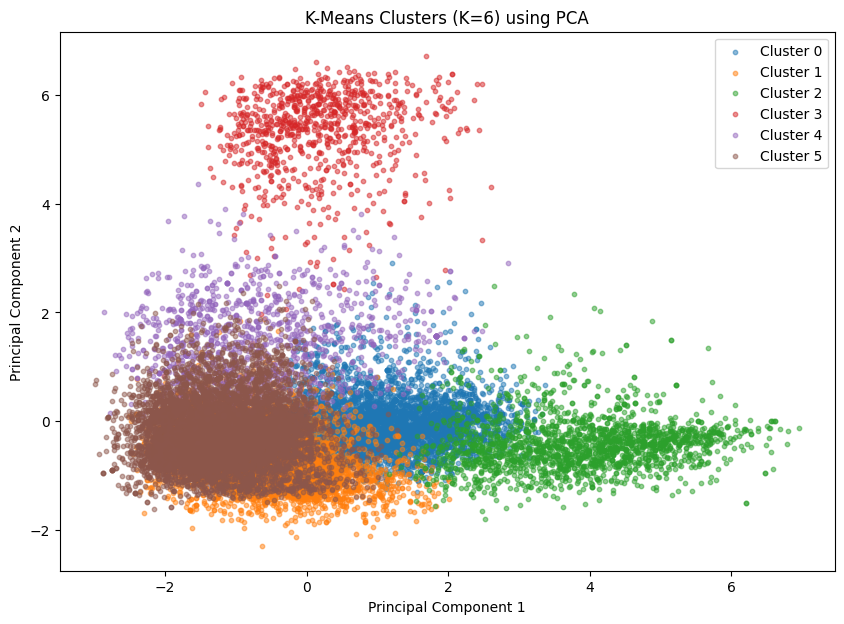

In [55]:
import matplotlib.pyplot as plt

pca_pd = (
    pca_result
    .select(
        "cluster",
        "pca_features"
    )
    .toPandas()
)

pca_pd["PC1"] = pca_pd["pca_features"].apply(lambda x: float(x[0]))
pca_pd["PC2"] = pca_pd["pca_features"].apply(lambda x: float(x[1]))

plt.figure(figsize=(10, 7))

for cluster in sorted(pca_pd["cluster"].unique()):
    subset = pca_pd[pca_pd["cluster"] == cluster]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=10
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (K=6) using PCA")
plt.legend()
plt.show()

In [56]:
final_df = k6_predictions.select(
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre",
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo",
    "speechiness",
    "instrumentalness",
    "liveness",
    "cluster"
)

final_df.printSchema()

root
 |-- track_id: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_genre: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- cluster: integer (nullable = false)



In [57]:
from pyspark.sql.functions import col, sum

print("Total rows:", final_df.count())
print("Total columns:", len(final_df.columns))

print("\nMissing values:")
final_df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in final_df.columns
]).show()

print("\nCluster distribution:")
final_df.groupBy("cluster").count().orderBy("cluster").show()

Total rows: 21639
Total columns: 16

Missing values:
+--------+----------+-------+----------+-----------+----------+------------+------+--------+------------+-------+-----+-----------+----------------+--------+-------+
|track_id|track_name|artists|album_name|track_genre|popularity|danceability|energy|loudness|acousticness|valence|tempo|speechiness|instrumentalness|liveness|cluster|
+--------+----------+-------+----------+-----------+----------+------------+------+--------+------------+-------+-----+-----------+----------------+--------+-------+
|       0|         0|      0|         0|          0|         0|           0|     0|       0|           0|      0|    0|          0|               0|       0|      0|
+--------+----------+-------+----------+-----------+----------+------------+------+--------+------------+-------+-----+-----------+----------------+--------+-------+


Cluster distribution:
+-------+-----+
|cluster|count|
+-------+-----+
|      0| 4852|
|      1| 4821|
|      2| 205

In [31]:
print("StandardScaler verification")
print("Mean vector:")
print(scaler_model.mean)

print("\nStandard deviation vector:")
print(scaler_model.std)

StandardScaler verification
Mean vector:
[0.5685087943065757,0.5991007979111814,-9.14435630112298,0.3659599104907831,0.4768194371274084,120.1800619252273,0.10417775775220661,0.19681915648736079,0.21173832432182565]

Standard deviation vector:
[0.17679200463295017,0.2609149785517111,5.49748819678939,0.3532813462773366,0.2613674419223806,29.361642690844143,0.17464315417383983,0.33947842594367267,0.19714895966328086]


In [32]:
from pyspark.ml.stat import Summarizer

stats = df_scaled.select(
    Summarizer.mean(col("scaled_features")).alias("mean"),
    Summarizer.std(col("scaled_features")).alias("std")
).collect()[0]

print("Scaled means:")
print(stats["mean"])

print("\nScaled standard deviations:")
print(stats["std"])

Scaled means:
[2.0389235005219275e-15,-9.594189727618954e-15,1.1752541909088423e-15,-6.694392761484591e-15,1.879660977647385e-15,9.948693344835613e-15,7.135710479531238e-16,2.459783678826488e-16,3.4647577775576144e-15]

Scaled standard deviations:
[0.9999999999999993,0.9999999999999988,0.9999999999999973,0.9999999999999968,0.9999999999999952,1.0000000000000022,1.000000000000003,1.0000000000000018,0.999999999999997]


In [46]:
test_path = "hdfs://localhost:9001/test_spotify/spark_test"
spark.range(2).write.mode("overwrite").parquet(test_path)

In [47]:
output_path = "hdfs://localhost:9001/data/spotify/processed/songs_clustered"

final_df.write.mode("overwrite").parquet(output_path)

In [48]:
check_df = spark.read.parquet(
    "hdfs://localhost:9001/data/spotify/processed/songs_clustered"
)

print("Rows:", check_df.count())
print("Columns:", len(check_df.columns))

check_df.printSchema()
check_df.show(5, truncate=False)

Rows: 21639
Columns: 16
root
 |-- track_id: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_genre: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- loudness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- cluster: integer (nullable = true)

+----------------------+--------------------------+----------------------+------------------------------------------------------+-----------+----------+------------+------+--------+------------+-------+-------+-----------+----------------+--------+-------+
|track_id              |track_name                |